In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("social_media_engagement_5000.csv")

In [4]:
df.shape
df.columns
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [5]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [6]:
likes_array = np.array(df['likes'].dropna())

print("Array:", likes_array)
print("Mean:", np.mean(likes_array))
print("Maximum:", np.max(likes_array))
print("Minimum:", np.min(likes_array))
print("Sum:", np.sum(likes_array))

Array: [ 7011. 11750.  4862. ... 13487. 16894. 14830.]
Mean: 10107.043711340206
Maximum: 19998.0
Minimum: 10.0
Sum: 49019162.0


In [7]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [8]:
df.isna().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [9]:
df['age'] = df['age'].fillna(df['age'].median())

df['likes'] = df['likes'].fillna(df['likes'].median())

df['comments'] = df['comments'].fillna(df['comments'].median())

df['shares'] = df['shares'].fillna(df['shares'].median())

In [ ]:
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])

df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

In [ ]:
df['age'] = df['age'].ffill()

In [ ]:
df['age'] = df['age'].bfill()

In [ ]:
df.duplicated().sum()

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df['gender'] = df['gender'].str.strip().str.lower()

df['post_type'] = df['post_type'].str.strip().str.lower()

df['sentiment'] = df['sentiment'].str.strip().str.lower()

df['device_type'] = df['device_type'].str.strip().str.lower()

In [ ]:
df['age'] = df['age'].where(
    df['age'].between(13, 100),
    df['age'].median()
)

df['likes'] = df['likes'].clip(lower=0)

df['comments'] = df['comments'].clip(lower=0)

df['shares'] = df['shares'].clip(lower=0)

In [ ]:
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(str(x).split())
)

In [ ]:
df['sentiment'] = df['sentiment'].str.lower().str.strip()

df['sentiment'].unique()

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df.info()

In [ ]:
df.dtypes

In [ ]:
df.describe()

In [10]:
df['gender'].value_counts()

gender
Male      1699
Other     1581
Female    1570
Name: count, dtype: int64

In [ ]:
df['post_type'].value_counts()

In [ ]:
df['country'].unique()

In [ ]:
df['country'].nunique()

In [ ]:
df['sentiment'].value_counts()

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

In [ ]:
df.groupby('post_type')['likes'].mean()

In [ ]:
df.groupby('country')['impression_count'].mean()

In [ ]:
df.groupby('sentiment')['engagement_rate'].mean()

In [11]:
df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

In [ ]:
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(str(x).split())
)

In [ ]:
df['log_likes'] = np.log1p(df['likes'])

df['log_comments'] = np.log1p(df['comments'])

df['log_shares'] = np.log1p(df['shares'])

In [ ]:
df.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

In [ ]:
df.groupby('country').agg({
    'likes': 'mean',
    'impression_count': 'mean',
    'engagement_rate': 'mean'
})

In [ ]:
df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

In [ ]:
columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

In [ ]:
df[columns].median()

In [ ]:
df[columns].mode()

In [ ]:
df[columns].std()

In [ ]:
df[columns].var()

In [ ]:
df[columns].quantile([0.25, 0.50, 0.75])

In [ ]:
df[columns].skew()

In [ ]:
df[columns].kurtosis()

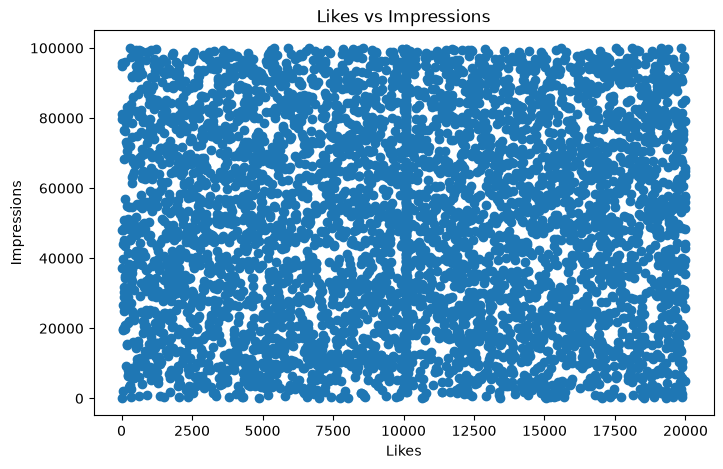

In [12]:
plt.figure(figsize=(8,5))

plt.scatter(df['likes'], df['impression_count'])

plt.xlabel('Likes')
plt.ylabel('Impressions')

plt.title('Likes vs Impressions')

plt.show()

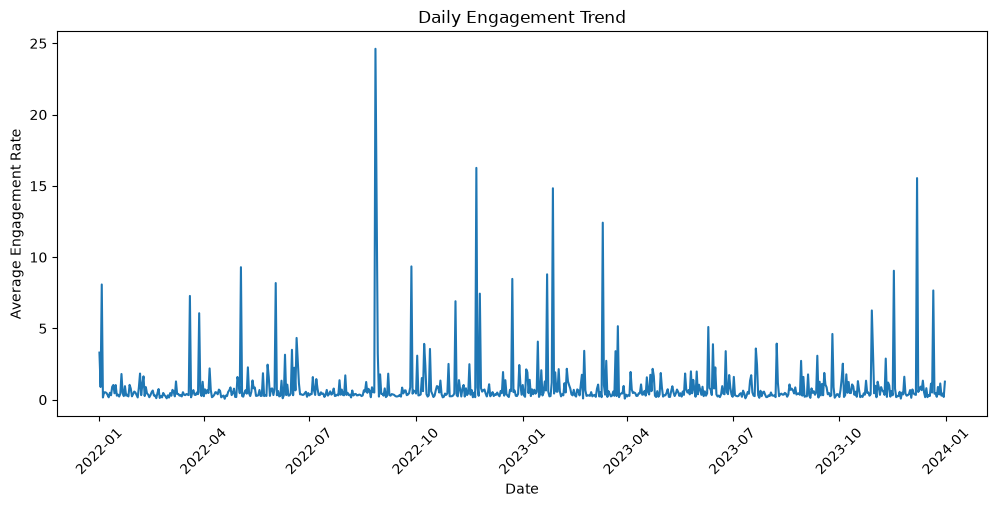

In [13]:
daily = df.groupby('posted_at')['engagement_rate'].mean()

plt.figure(figsize=(12,5))

plt.plot(daily.index, daily.values)

plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')

plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)

plt.show()

In [14]:
plt.figure(figsize=(9,5))

plt.bar(category.index, category.values)

plt.xlabel('Category')
plt.ylabel('Number of Posts')

plt.title('Posts by Category')

plt.xticks(rotation=45)

plt.show()

NameError: name 'category' is not defined

<Figure size 900x500 with 0 Axes>

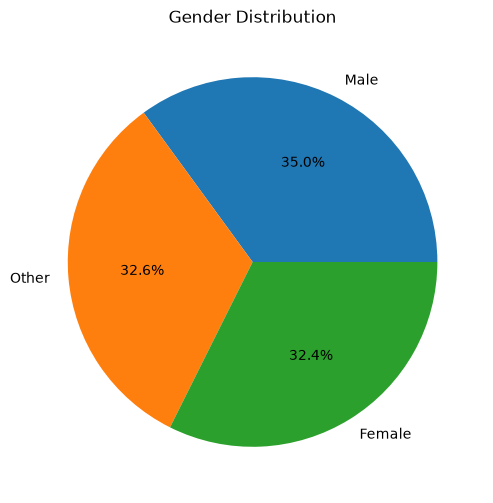

In [15]:
gender = df['gender'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    gender.values,
    labels=gender.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

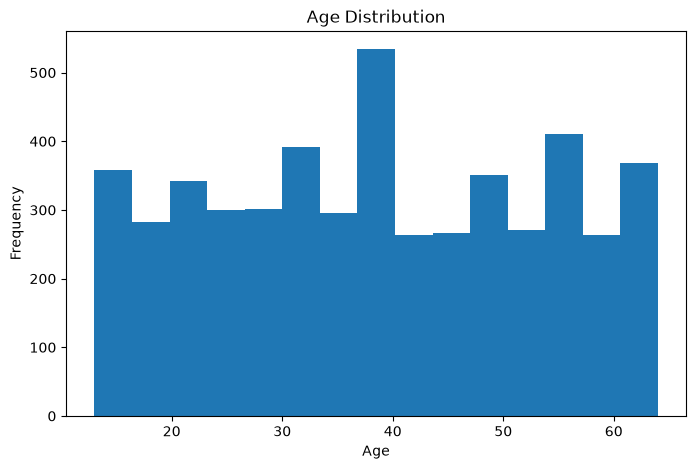

In [16]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=15)

plt.xlabel('Age')
plt.ylabel('Frequency')

plt.title('Age Distribution')

plt.show()

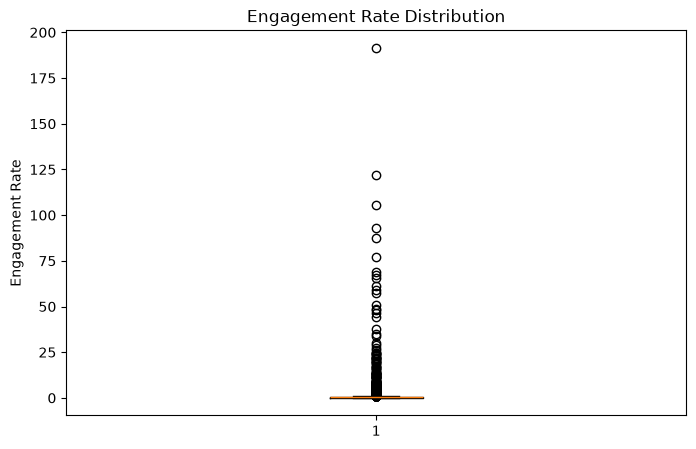

In [17]:
plt.figure(figsize=(8,5))

plt.boxplot(df['engagement_rate'])

plt.ylabel('Engagement Rate')

plt.title('Engagement Rate Distribution')

plt.show()

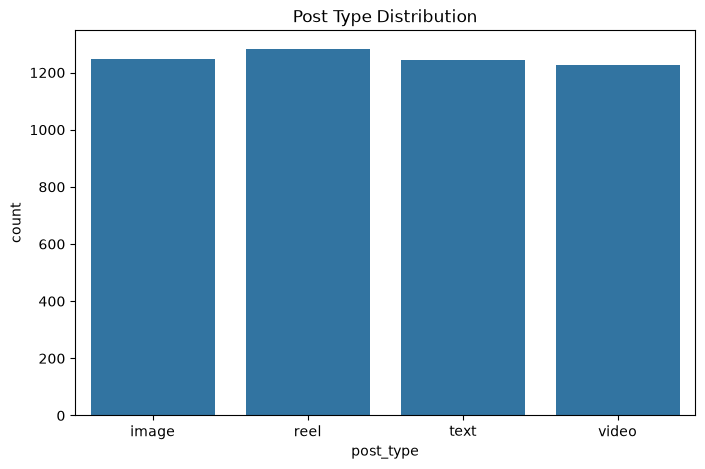

In [18]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='post_type')

plt.title('Post Type Distribution')

plt.show()

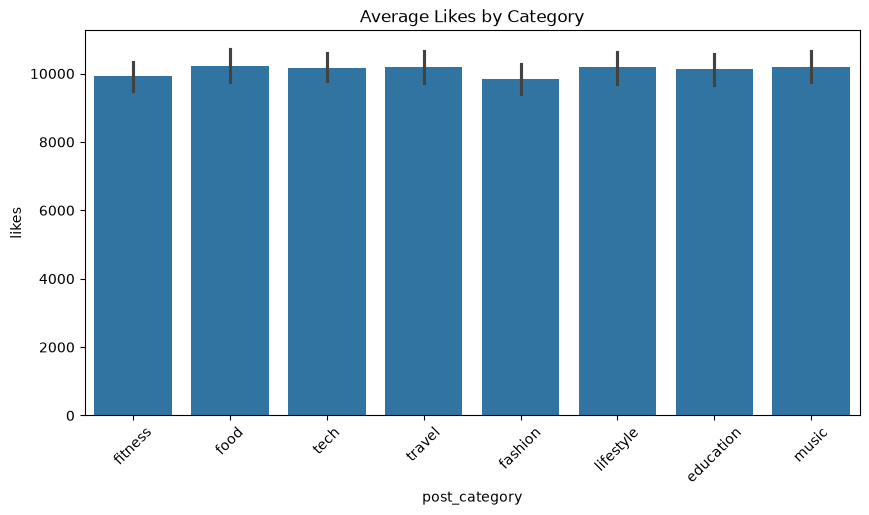

In [19]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes'
)

plt.xticks(rotation=45)

plt.title('Average Likes by Category')

plt.show()

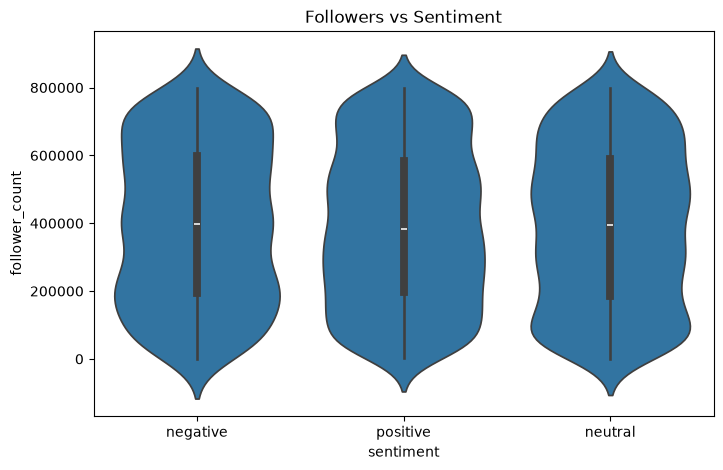

In [20]:
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Followers vs Sentiment')

plt.show()

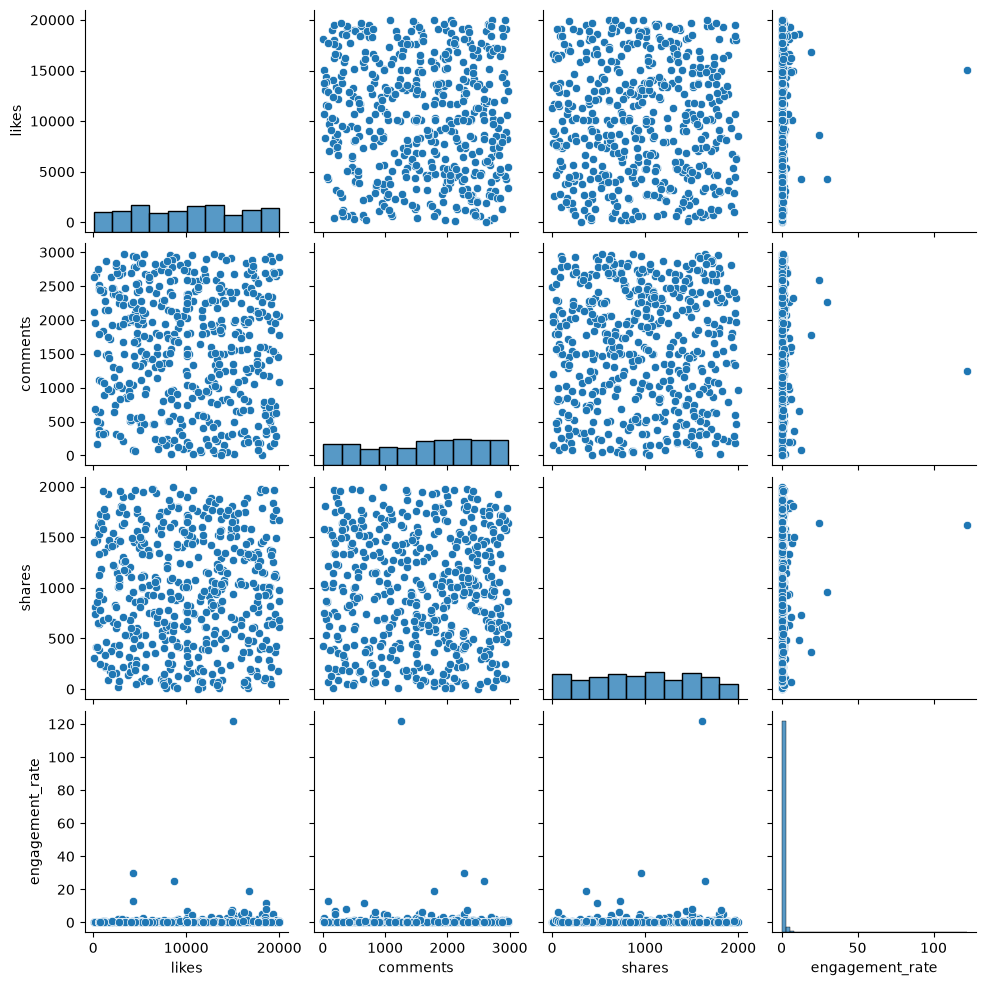

In [21]:
sns.pairplot(
    df[['likes', 'comments', 'shares', 'engagement_rate']].sample(
        min(500, len(df)),
        random_state=42
    )
)

plt.show()

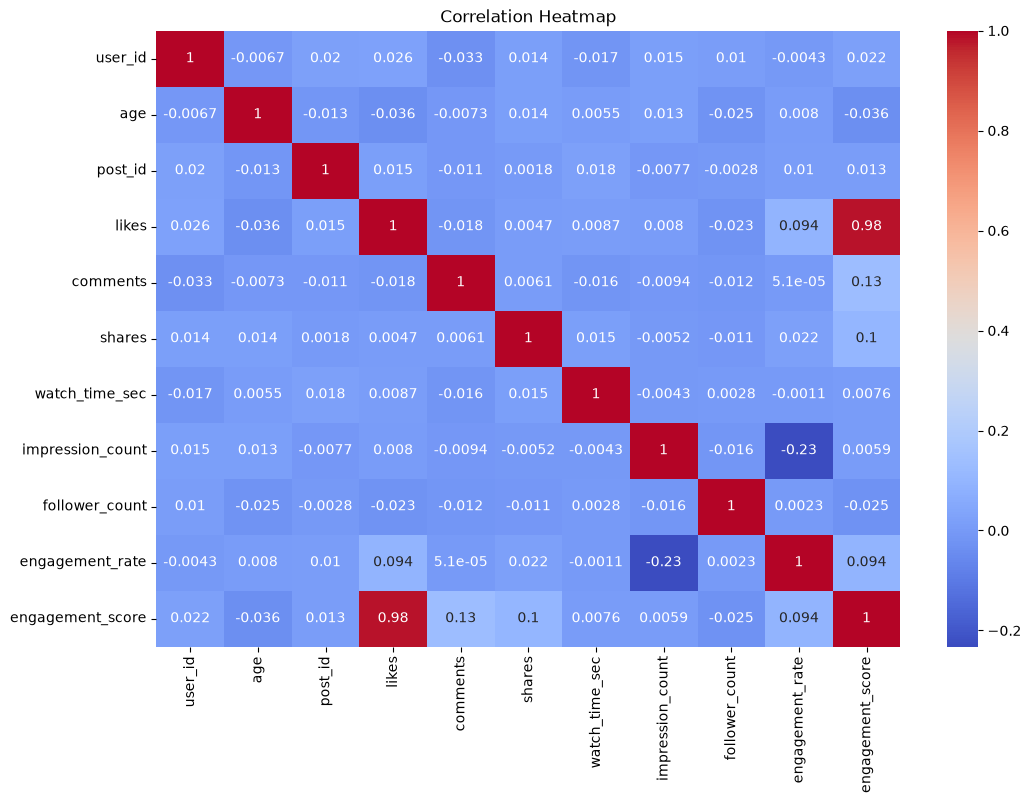

In [22]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

c:\Users\RAHIM\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\RAHIM\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 45.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\RAHIM\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 42.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\RAHIM\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 41.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(ms

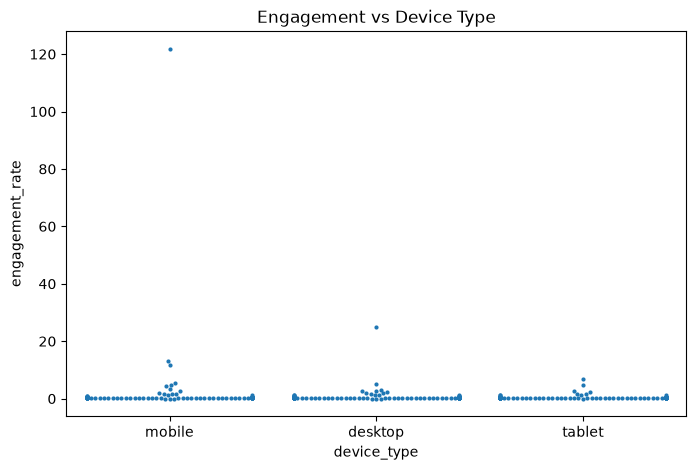

In [23]:
sample = df.sample(min(300, len(df)), random_state=42)

plt.figure(figsize=(8,5))

sns.swarmplot(
    data=sample,
    x='device_type',
    y='engagement_rate',
    size=3
)

plt.title('Engagement vs Device Type')

plt.show()

In [ ]:
fig = px.line(
    daily.reset_index(),
    x='posted_at',
    y='engagement_rate',
    title='Interactive Daily Engagement Trend'
)

fig.show()

In [ ]:
fig = px.bar(
    df.groupby('post_category', as_index=False)['likes'].mean(),
    x='post_category',
    y='likes',
    title='Average Likes by Category'
)

fig.show()

In [ ]:
fig = px.scatter(
    df,
    x='likes',
    y='impression_count',
    color='post_type',
    title='Likes vs Impressions'
)

fig.show()

In [24]:
#1. Which post type has the highest engagement?
df.groupby('post_type')['engagement_rate'].mean().sort_values(
    ascending=False
)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

In [25]:
#Best-performing content category
df.groupby('post_category')['likes'].mean().sort_values(
    ascending=False
)


post_category
food         10225.522766
music        10205.749606
travel       10196.304167
lifestyle    10180.559308
tech         10171.571429
education    10126.487322
fitness       9914.602222
fashion       9843.356902
Name: likes, dtype: float64

In [26]:
#Which countries have the highest average engagement
df.groupby('country')['engagement_rate'].mean().sort_values(
    ascending=False
)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [27]:
#How does age affect engagement?
df.groupby(
    pd.cut(df['age'], bins=[12, 20, 30, 40, 50, 60, 100])
)['engagement_rate'].mean()

age
(12, 20]     0.802733
(20, 30]     1.018917
(30, 40]     0.843572
(40, 50]     1.103215
(50, 60]     1.106470
(60, 100]    0.801381
Name: engagement_rate, dtype: float64

In [28]:
#Best time of day for impressions
df['posted_at'].head()


0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[us]

In [29]:
#Device type impact on watch time
df.groupby('device_type')['watch_time_sec'].mean().sort_values(
    ascending=False
)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

In [30]:
#Which sentiment performs best?
df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
}).sort_values('engagement_rate', ascending=False)

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170
positive,10156.926788,1482.401608,1001.880660,0.954800


In [ ]:
#Negative and neutral sentiment behaviour26

In [31]:
df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
}).sort_values('engagement_rate', ascending=False)

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170
positive,10156.926788,1482.401608,1001.880660,0.954800
